# PetPulse — IA da Sprint 4

**Disruptive Architectures: IoT, IoB & Generative IA · Challenge CLYVO VET · FIAP 2026 · 2TDSPG**

Gabriel Neris Losano (RM564093) · João Vitor Biribilli Ravelli (RM565594) · Pedro de Matos Previtali (RM564184) · Pietro Paranhos Wilhelm (RM561378)

Na Sprint 3 definimos que a IA do PetPulse não ia usar limites fixos ("FC acima de 180 = alerta"), porque cada pet tem um normal diferente. A ideia era aprender o padrão de cada animal com os dados da coleira, detectar quando ele sai desse padrão e explicar isso para o tutor em linguagem simples.

Neste notebook mostramos essa IA funcionando, passo a passo:

1. dados da coleira (gerados e validados);
2. **Pilar 1**: baseline individual de cada pet;
3. **Pilar 2**: detecção de anomalias com Isolation Forest;
4. matriz de severidade e contexto clínico (vacina, medicação);
5. **Pilar 3**: alerta escrito pelo Gemini, com validação (guardrails);
6. simulações pela API, com o mesmo JSON que a nossa API Java envia;
7. avaliação comparando a IA com as regras fixas que usávamos antes.

### Como rodar (só precisa da chave do Gemini)

1. No Colab, abra o ícone de chave 🔑 (**Secrets**) e crie o secret `GEMINI_API_KEY` com a sua chave do [Google AI Studio](https://aistudio.google.com/apikey). Deixe o acesso do notebook ativado.
2. Menu **Ambiente de execução → Executar tudo**.

Rodando fora do Colab (Jupyter ou VS Code na pasta do repositório), copie o arquivo `.env.example` para `.env` e cole a sua chave em `GEMINI_API_KEY`.

## 1. Instalação

In [1]:
%pip install -q -U "google-genai>=2.3.0" scikit-learn pydantic pandas matplotlib fastapi httpx python-dotenv

Note: you may need to restart the kernel to use updated packages.


## 2. Código do projeto

O motor de IA fica na pasta `app/` do repositório. Ele é o mesmo código que roda no serviço FastAPI chamado pela API Java. No Colab, a célula abaixo clona o repositório; se o notebook já estiver aberto dentro da pasta do projeto, ela não faz nada.

In [2]:
import logging
import os
import subprocess
import sys
import warnings

if not os.path.exists("app"):
    subprocess.run(["git", "clone", "-q", "https://github.com/Fiap-2tdspg-Challenge/PetPulse-AI.git"], check=True)
    os.chdir("PetPulse-AI")

sys.path.insert(0, os.getcwd())
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", module="fastapi.testclient")
logging.getLogger("httpx").setLevel(logging.WARNING)
print("Código do projeto carregado de:", os.path.basename(os.getcwd()))

Código do projeto carregado de: PetPulse-AI


## 3. Chave do Gemini

A chave nunca fica escrita no código. No Colab ela vem dos Secrets (`userdata.get`, igual aos labs); fora do Colab, do arquivo `.env`, que está no `.gitignore` e não vai para o GitHub. Usamos o SDK `google-genai` com a Interactions API, como nos labs 2 e 3.

In [3]:
from google import genai

try:
    from google.colab import userdata
    GEMINI_API_KEY = userdata.get("GEMINI_API_KEY")
except ImportError:
    from dotenv import load_dotenv
    load_dotenv()  # fora do Colab: lê o .env da pasta do projeto
    GEMINI_API_KEY = os.getenv("GEMINI_API_KEY")

assert GEMINI_API_KEY, "Configure a GEMINI_API_KEY nos Secrets do Colab ou no arquivo .env do projeto."
os.environ["GEMINI_API_KEY"] = GEMINI_API_KEY  # o serviço FastAPI (seção 10) lê a chave daqui

MODEL = "gemini-3.5-flash"
client = genai.Client(api_key=GEMINI_API_KEY)

teste = client.interactions.create(model=MODEL, input="Responda apenas com a palavra OK.")
print("Gemini respondeu:", teste.output_text)

Gemini respondeu: OK


## 4. Dados da coleira

Não encontramos nenhuma base pública com telemetria de coleiras e anomalias marcadas. Por isso geramos um dataset sintético com semente fixa (o resultado é sempre o mesmo): **14 dias, uma leitura a cada 10 minutos, para 4 pets** com fisiologias bem diferentes:

| Pet | Perfil | Por que escolhemos |
|---|---|---|
| Thor | Labrador, 6 anos | FC de repouso ~85 bpm |
| Mel | Chihuahua idosa, 11 anos | FC alta e vacina no meio do período |
| Nina | Gata, 4 anos | FC normal acima de 160 bpm |
| Bob | Border Collie atleta | dorme com ~48 bpm |

O gerador simula ciclo de sono, passeios, corridas, fim de semana, ruído do sensor, falhas de leitura e alguns valores impossíveis (999 bpm, por exemplo). Depois colocamos **7 episódios marcados**: 5 em que a IA deveria alertar e 2 em que **não** deveria (reação leve de vacina e um pico isolado do sensor).

In [4]:
import json
from datetime import datetime, timedelta

import matplotlib.pyplot as plt
import pandas as pd

from dados.gerar_dataset import gerar as gerar_dataset

gerar_dataset()  # semente 42 = dataset de desenvolvimento
leituras = pd.read_csv("dados/leituras.csv", parse_dates=["dataLeitura"])
episodios = pd.read_json("dados/episodios.json")

display(leituras.head())
display(episodios[["id", "petId", "inicio", "horas", "deveAlertar", "nivelEsperado", "descricao"]])

8064 leituras de 4 pets e 7 episódios rotulados gerados em dados/


,petId,dataLeitura,frequenciaCardiaca,nivelAtividade,pressao,temperatura,episodio
0,1,2026-10-01 00:00:00,66.0,6.2,134,38.53,NaN
1,1,2026-10-01 00:10:00,68.0,3.5,134,38.58,NaN
2,1,2026-10-01 00:20:00,68.0,6.9,136,38.54,NaN
3,1,2026-10-01 00:30:00,64.0,5.6,128,38.52,NaN
4,1,2026-10-01 00:40:00,60.0,0.8,134,38.45,NaN


,id,petId,inicio,horas,deveAlertar,nivelEsperado,descricao
0,E1,1,2026-10-10T13:00,8.0,True,MEDIO,Taquicardia em repouso: FC 30% acima do padrão...
1,E2,1,2026-10-12T10:20,0.1,False,NaN,Artefato de sensor: uma leitura isolada de 205...
2,E3,2,2026-10-09T10:00,30.0,False,BAIXO,"Reação vacinal esperada: +0,5 °C e -35% de ati..."
3,E4,2,2026-10-13T02:00,30.0,True,ALTO,"Febre em repouso com prostração (39,9 °C, -60%..."
4,E5,3,2026-10-09T08:00,60.0,True,MEDIO,Hipertensão progressiva: pressão sobe até +45 ...
5,E6,3,2026-10-13T00:00,36.0,True,MEDIO,Prostração: queda de 55% na movimentação
6,E7,4,2026-10-11T15:00,7.0,True,MEDIO,Taquicardia em repouso: FC 38% acima do padrão...


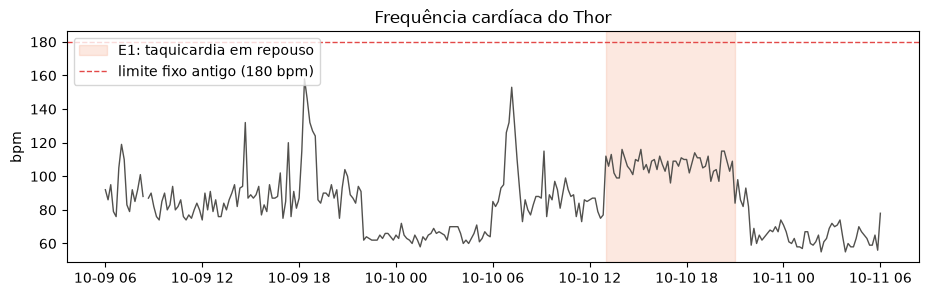

In [5]:
# Thor durante dois dias: o episódio E1 (taquicardia em repouso) está sombreado
thor = leituras[(leituras.petId == 1) & (leituras.dataLeitura.between("2026-10-09 06:00", "2026-10-11 06:00"))]
e1 = episodios.set_index("id").loc["E1"]
inicio_e1 = pd.Timestamp(e1.inicio)

fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(thor.dataLeitura, thor.frequenciaCardiaca, linewidth=1, color="#52514e")
ax.axvspan(inicio_e1, inicio_e1 + pd.Timedelta(hours=e1.horas), color="#eb6834", alpha=0.15, label="E1: taquicardia em repouso")
ax.axhline(180, color="#e34948", linestyle="--", linewidth=1, label="limite fixo antigo (180 bpm)")
ax.set_ylabel("bpm")
ax.set_title("Frequência cardíaca do Thor")
ax.legend(loc="upper left")
plt.show()

O episódio fica bem visível no gráfico, mas nunca chega perto do limite fixo de 180 bpm. A regra antiga da API nunca avisaria o tutor.

## 5. Preparação e validação dos dados

Antes de qualquer análise, cada leitura passa por um modelo Pydantic (`app/schemas.py`) e pela função `preparar` (`app/ml/preparacao.py`), que:
- ordena e remove leituras repetidas no mesmo horário;
- descarta valores fisicamente impossíveis do sensor (por exemplo, FC fora de 20–350);
- converte pressão em cmHg para mmHg (os exemplos antigos da nossa API usavam 13 em vez de 130).

In [6]:
from pydantic import ValidationError

from app.ml.preparacao import preparar
from app.schemas import Leitura

t0 = datetime(2026, 10, 1, 12, 0)
sujas = [
    Leitura(data_leitura=t0 + timedelta(minutes=10), frequencia_cardiaca=999, pressao=13),  # FC impossível e pressão em cmHg
    Leitura(data_leitura=t0, frequencia_cardiaca=82, pressao=131),
    Leitura(data_leitura=t0, frequencia_cardiaca=85, pressao=132),                          # reenvio do mesmo horário
]
serie = preparar(sujas)
print("datas:", serie.datas)
print("FC:", serie.valores["frequencia_cardiaca"], "| pressão:", serie.valores["pressao"])
print("valores descartados:", serie.descartados)

try:
    Leitura(data_leitura="ontem", frequencia_cardiaca=-5)
except ValidationError as erro:
    print("\nLeitura inválida recusada pelo Pydantic:", erro.error_count(), "erro(s)")

datas: [datetime.datetime(2026, 10, 1, 12, 0), datetime.datetime(2026, 10, 1, 12, 10)]
FC: [85. nan] | pressão: [132. 130.]
valores descartados: 1

Leitura inválida recusada pelo Pydantic: 2 erro(s)


## 6. Pilar 1: baseline individual

Para cada pet e cada contexto (repouso de dia, repouso à noite, caminhada, corrida), o motor aprende qual é o valor esperado de FC, temperatura e pressão. Dentro do contexto, ele usa uma regressão linear simples com o nível de atividade do momento. A variação normal é medida com mediana e MAD, que não são distorcidas por alguns valores estranhos no histórico.

Comparando Thor e Bob dá para ver por que uma régua única não funciona:

In [7]:
from app.ml.baseline import BaselineIndividual
from avaliacao.dataset import carregar_episodios, carregar_leituras, carregar_pets

pets = carregar_pets()
dados_pets = carregar_leituras()
eps = {e["id"]: e for e in carregar_episodios()}


def serie_ate(pet_id, ate):
    return preparar([l for l, _ in dados_pets[pet_id] if l.data_leitura <= ate])


for pet_id in (1, 2, 3, 4):
    perfil = pets[pet_id][0]
    base = BaselineIndividual(serie_ate(pet_id, datetime(2026, 10, 9)))
    dia = base.modelo("frequencia_cardiaca", 0)    # 0 = repouso durante o dia
    noite = base.modelo("frequencia_cardiaca", 3)  # 3 = repouso noturno
    print(f"{perfil.nome:5} ({perfil.raca}): FC esperada em repouso de dia ≈ {dia.esperado(10):.0f} bpm, "
          f"dormindo ≈ {noite.esperado(3):.0f} bpm")

Thor  (Labrador): FC esperada em repouso de dia ≈ 83 bpm, dormindo ≈ 62 bpm
Mel   (Chihuahua): FC esperada em repouso de dia ≈ 126 bpm, dormindo ≈ 107 bpm
Nina  (SRD): FC esperada em repouso de dia ≈ 171 bpm, dormindo ≈ 151 bpm
Bob   (Border Collie): FC esperada em repouso de dia ≈ 67 bpm, dormindo ≈ 50 bpm


O Bob dorme com uns 50 bpm e a Nina descansa acima de 160. Com a régua antiga (60 a 180), o Bob geraria alerta toda noite, e a taquicardia do Thor (~107 bpm) passaria despercebida.

## 7. Pilar 2: Isolation Forest

Treinamos um Isolation Forest (scikit-learn) **por pet**, só com o histórico dele. As entradas são FC, temperatura, pressão, atividade e hora do dia. O modelo isola pontos raros com poucos cortes aleatórios, então combinações estranhas (FC alta com o pet parado, por exemplo) recebem score alto.

O score vai de 0 a 1 e indica que fração do histórico do pet é menos incomum que a leitura (1 = mais estranha que todo o histórico). Abaixo comparamos o score médio durante cada episódio com o do mesmo horário no dia anterior:

In [8]:
import numpy as np

from app.ml.detector import DetectorMultivariado, montar_matriz


def janela(pet_id, inicio, horas):
    serie = serie_ate(pet_id, inicio + timedelta(hours=horas))
    return serie.recorte(np.array([d >= inicio for d in serie.datas]))


for ep_id in ("E1", "E7", "E4"):
    ep = eps[ep_id]
    pet_id = ep["petId"]
    nome = pets[pet_id][0].nome
    treino = serie_ate(pet_id, ep["inicio"] - timedelta(days=1))
    detector = DetectorMultivariado().treinar(montar_matriz(treino))

    durante = montar_matriz(janela(pet_id, ep["inicio"], min(ep["horas"], 8)))
    dia_antes = montar_matriz(janela(pet_id, ep["inicio"] - timedelta(days=1), min(ep["horas"], 8)))
    print(f"{nome:5} {ep_id}: score médio no episódio {detector.percentil_anomalia(durante).mean():.2f} | "
          f"mesmo horário no dia anterior {detector.percentil_anomalia(dia_antes).mean():.2f} | "
          f"leituras marcadas como anômalas no episódio: {detector.anomalo(durante).mean():.0%}")

Thor  E1: score médio no episódio 0.85 | mesmo horário no dia anterior 0.55 | leituras marcadas como anômalas no episódio: 0%
Bob   E7: score médio no episódio 0.82 | mesmo horário no dia anterior 0.58 | leituras marcadas como anômalas no episódio: 0%


Mel   E4: score médio no episódio 0.92 | mesmo horário no dia anterior 0.51 | leituras marcadas como anômalas no episódio: 10%


O score sobe bastante nos episódios, mas o Isolation Forest sozinho marca poucas leituras como "anômalas", porque configuramos para ele considerar só os 2% mais raros do histórico. Por isso, no motor ele não decide sozinho: serve para **confirmar desvios moderados** (|z| entre 2 e 3) e para dar o `scoreAnomalia` que vai para o veterinário. Quem decide é a baseline individual, como mostra a avaliação na seção 11.

## 8. Motor completo: matriz de severidade e contexto clínico

O motor (`app/ml/motor.py`) junta tudo e aplica a matriz de severidade que definimos na Sprint 3:

| Nível | Quando | O que acontece |
|---|---|---|
| BAIXO | desvio isolado | só fica registrado, sem notificar |
| MÉDIO | desvio que persiste por horas, ou vários sinais juntos | alerta e recomendação de consulta |
| ALTO | sinais combinados e severos, ou limite crítico confirmado | alerta urgente e notificação no celular |

Ele também olha o histórico clínico: se o pet tomou vacina há menos de 72 h e a alteração é leve e compatível com reação vacinal, o nível cai um degrau.

Rodando o motor em um momento de cada episódio:

In [9]:
from app.ml.motor import MotorAnomalias

motor = MotorAnomalias()
momentos = [("E1", 6), ("E2", 0), ("E3", 27), ("E4", 15), ("E5", 54), ("E6", 30), ("E7", 5)]

linhas = []
for ep_id, horas in momentos:
    ep = eps[ep_id]
    perfil, historico = pets[ep["petId"]]
    r = motor.analisar_serie(perfil, serie_ate(ep["petId"], ep["inicio"] + timedelta(hours=horas)), historico)
    linhas.append({
        "episódio": ep_id,
        "pet": perfil.nome,
        "deveria alertar?": "sim" if ep["deveAlertar"] else "não",
        "nível da IA": r.nivel_risco or "-",
        "gera alerta?": "sim" if r.gerar_alerta else "não",
        "por quê": " ".join(r.justificativa),
    })

pd.set_option("display.max_colwidth", None)
pd.DataFrame(linhas)

,episódio,pet,deveria alertar?,nível da IA,gera alerta?,por quê
0,E1,Thor,sim,MEDIO,sim,Desvio persistente em frequencia_cardiaca → MEDIO.
1,E2,Thor,não,BAIXO,não,Desvio isolado sem persistência (frequencia_cardiaca) → BAIXO (registro e monitoramento passivo).
2,E3,Mel,não,BAIXO,não,Desvio persistente em atividade → MEDIO. Vacina recente (Antirrábica): alterações leves de temperatura e atividade são esperadas até 72 h após a aplicação → rebaixado de MEDIO para BAIXO.
3,E4,Mel,sim,ALTO,sim,"Desvios sustentados combinados e severos (atividade, temperatura) → ALTO."
4,E5,Nina,sim,ALTO,sim,Limite crítico ultrapassado em leituras consecutivas: pressao → ALTO.
5,E6,Nina,sim,MEDIO,sim,Desvio persistente em atividade → MEDIO.
6,E7,Bob,sim,MEDIO,sim,Desvio persistente em frequencia_cardiaca → MEDIO.


## 9. Pilar 3: alerta contextual com o Gemini

Aqui aplicamos o que vimos nos labs 1 e 3:
- **engenharia de prompt**: persona, tarefa, regras, formato e um exemplo few-shot (`app/genai/prompts.py`);
- **saída estruturada**: o Gemini devolve JSON validado por uma classe Pydantic com título, mensagem e recomendação.

Uma decisão importante do grupo: **o Gemini não decide o nível de risco**, só escreve o texto. Quem decide é o motor da seção 8 (igual ao Checkpoint 4, em que o modelo não podia calcular o preço). O modelo recebe só os fatos calculados:

In [10]:
from app.genai.alerta import AlertaContextual, RedatorAlertas, montar_fatos, validar_texto

redator = RedatorAlertas(cliente=client, modelo=MODEL)

perfil, historico = pets[1]
resultado = motor.analisar_serie(perfil, serie_ate(1, eps["E1"]["inicio"] + timedelta(hours=6)), historico)
fatos = montar_fatos(perfil, resultado)
print("Fatos enviados ao Gemini:")
print(json.dumps(fatos, ensure_ascii=False, indent=2))

texto, motivo = redator.redigir(perfil, resultado)
print("\nAlerta final:")
print(texto.model_dump_json(indent=2))
print("Motivo de fallback:", motivo)

Fatos enviados ao Gemini:
{
  "pet": {
    "nome": "Thor",
    "especie": "cão",
    "raca": "Labrador",
    "idade_anos": 6.0,
    "artigo": "do"
  },
  "nivel_risco": "MEDIO",
  "conduta_obrigatoria": "Recomendar observar o pet e agendar consulta de rotina com o veterinário.",
  "desvios": [
    {
      "sinal": "frequência cardíaca",
      "tipo": "persistente",
      "direcao": "acima",
      "valor_atual": "108 bpm",
      "padrao_do_pet": "82 bpm",
      "variacao": "32%",
      "contexto": "em repouso",
      "duracao_horas": 6
    }
  ],
  "contexto_clinico": [
    "Consulta em 03/10: Check-up anual sem alterações"
  ]
}



Alerta final:
{
  "titulo": "Frequência cardíaca do Thor acima do padrão",
  "mensagem": "A frequência cardíaca do Thor em repouso está 32% acima do padrão dele há 6 horas, registrando 108 bpm quando o habitual é 82 bpm. O histórico mostra uma consulta em 03/10 com check-up anual sem alterações.",
  "recomendacao": "Recomendamos observar o pet e agendar uma consulta de rotina com o veterinário.",
  "gerado_por": "gemini"
}
Motivo de fallback: None


Antes de aceitar o texto do Gemini, o código confere (guardrails):
- se todo número do texto existe nos fatos (evita alucinação);
- se não há remédio nem dose;
- se o nome do pet aparece;
- se o texto cabe nas colunas do Oracle.

Se algo falhar (ou o Gemini estiver fora do ar), o sistema usa um texto padrão e o tutor continua sendo avisado. Exemplos de textos que seriam rejeitados:

In [11]:
numero_inventado = AlertaContextual(
    titulo="FC alta do Thor",
    mensagem="A FC do Thor subiu 45% nas últimas 12 horas.",
    recomendacao="Agende uma consulta de rotina com o veterinário.",
)
com_remedio = AlertaContextual(
    titulo="FC alta do Thor",
    mensagem="A frequência cardíaca do Thor está 32% acima do padrão dele.",
    recomendacao="Dê meio comprimido de dipirona e observe.",
)
print("Número inventado →", validar_texto(numero_inventado, fatos, perfil))
print("Remédio          →", validar_texto(com_remedio, fatos, perfil))

Número inventado → número 45 não existe nos fatos (possível alucinação)
Remédio          → menção proibida a medicamento/dose: 'comprimido'


## 10. Simulações pela API

Na aplicação, quem chama a IA é a nossa API Java. A cada leitura da coleira, ela envia para `POST /v1/analises` o perfil do pet, as leituras dos últimos 14 dias e o histórico clínico. Se a resposta vier com `gerarAlerta = true`, a API grava o alerta no Oracle e o app mostra para o tutor.

Aqui subimos o mesmo serviço FastAPI dentro do notebook e mandamos o mesmo JSON, em quatro cenários (como as simulações do Checkpoint 4):

In [12]:
from fastapi.testclient import TestClient

from app.main import app

api = TestClient(app)
print(api.get("/health").json())


def simular(ep_id, horas_depois_do_inicio):
    ep = eps[ep_id]
    perfil, historico = pets[ep["petId"]]
    ate = ep["inicio"] + timedelta(hours=horas_depois_do_inicio)
    corpo = {
        "pet": perfil.model_dump(by_alias=True),
        "leituras": [l.model_dump(mode="json", by_alias=True)
                     for l, _ in dados_pets[ep["petId"]] if l.data_leitura <= ate][-2016:],
        "historicoClinico": [e.model_dump(mode="json", by_alias=True) for e in historico],
    }
    r = api.post("/v1/analises", json=corpo).json()
    print(f"{perfil.nome}: {ep['descricao']}")
    print(f"  nível: {r['nivelRisco']} | gera alerta: {r['gerarAlerta']} | tipo: {r['tipoAlerta']}")
    if r["alerta"]:
        print(f"  [{r['alerta']['geradoPor']}] {r['alerta']['titulo']}")
        print(f"  {r['alerta']['mensagem']}")
        print(f"  → {r['alerta']['recomendacao']}")
    print("  justificativa:", " ".join(r["justificativa"]))

{'status': 'UP', 'versao': '1.0.0', 'textoDosAlertas': 'gemini-3.5-flash'}


**Simulação 1:** taquicardia do Thor em repouso. Deve gerar alerta MÉDIO.

In [13]:
simular("E1", 6)

2026-11-01 15:20:23,110 INFO petpulse-ai: pet=1 nivel=MEDIO alerta=True texto=gemini modo=baseline_individual leituras=1411 8718ms


Thor: Taquicardia em repouso: FC 30% acima do padrão do Thor (~107 bpm, abaixo do limite fixo de 180)
  nível: MEDIO | gera alerta: True | tipo: FREQUENCIA_CARDIACA
  [gemini] Frequência cardíaca do Thor acima do padrão
  A frequência cardíaca do Thor em repouso está 32% acima do padrão dele há 6 horas, registrando 108 bpm quando o seu habitual é 82 bpm. Em seu histórico, consta uma consulta em 03/10 com check-up anual sem alterações.
  → Recomendamos observar o Thor e agendar uma consulta de rotina com o veterinário.
  justificativa: Desvio persistente em frequencia_cardiaca → MEDIO.


**Simulação 2:** reação leve da Mel depois da vacina. Não deve virar alerta.

In [14]:
simular("E3", 27)

2026-11-01 15:20:23,289 INFO petpulse-ai: pet=2 nivel=BAIXO alerta=False texto=- modo=baseline_individual leituras=1375 160ms


Mel: Reação vacinal esperada: +0,5 °C e -35% de atividade
  nível: BAIXO | gera alerta: False | tipo: ATIVIDADE
  justificativa: Desvio persistente em atividade → MEDIO. Vacina recente (Antirrábica): alterações leves de temperatura e atividade são esperadas até 72 h após a aplicação → rebaixado de MEDIO para BAIXO.


**Simulação 3:** febre com prostração da Mel. Deve gerar alerta ALTO (notificação no celular).

In [15]:
simular("E4", 15)

2026-11-01 15:20:33,647 INFO petpulse-ai: pet=2 nivel=ALTO alerta=True texto=gemini modo=baseline_individual leituras=1831 10339ms


Mel: Febre em repouso com prostração (39,9 °C, -60% de atividade)
  nível: ALTO | gera alerta: True | tipo: ANOMALIA_MULTIVARIADA
  [gemini] Alterações na temperatura e movimentação da Mel
  A temperatura da Mel em repouso está 1,2 °C acima do padrão dela há 6 horas (39,9 °C, sendo 38,7 °C o habitual) e sua movimentação caiu 43% nas últimas 24 horas (de 13 % para 8 %). Como histórico, ela tomou a vacina Antirrábica em 09/10 e tem registro de Condroitina em 02/10.
  → Recomendamos procurar atendimento veterinário imediato.
  justificativa: Desvios sustentados combinados e severos (atividade, temperatura) → ALTO.


**Simulação 4:** pico isolado de 205 bpm (erro do sensor). Não deve virar alerta.

In [16]:
simular("E2", 0)

2026-11-01 15:20:33,838 INFO petpulse-ai: pet=1 nivel=BAIXO alerta=False texto=- modo=baseline_individual leituras=1647 170ms


Thor: Artefato de sensor: uma leitura isolada de 205 bpm
  nível: BAIXO | gera alerta: False | tipo: FREQUENCIA_CARDIACA
  justificativa: Desvio isolado sem persistência (frequencia_cardiaca) → BAIXO (registro e monitoramento passivo).


**Histórico salvo no banco.** Como pede o Lab 3.5, o serviço grava cada análise num SQLite (`app/repositorio.py`), inclusive as de nível BAIXO, que não viram alerta, junto com a justificativa e a origem do texto (Gemini ou padrão). O histórico é consultado por `GET /v1/analises`:

In [17]:
historico = pd.DataFrame(api.get("/v1/analises", params={"limite": 4}).json())
historico[["id", "petId", "nivelRisco", "gerarAlerta", "tipoAlerta", "textoGeradoPor", "duracaoMs", "mensagem"]]

,id,petId,nivelRisco,gerarAlerta,tipoAlerta,textoGeradoPor,duracaoMs,mensagem
0,4,1,BAIXO,False,FREQUENCIA_CARDIACA,NaN,169.8,NaN
1,3,2,ALTO,True,ANOMALIA_MULTIVARIADA,gemini,10339.4,"A temperatura da Mel em repouso está 1,2 °C acima do padrão dela há 6 horas (39,9 °C, sendo 38,7 °C o habitual) e sua movimentação caiu 43% nas últimas 24 horas (de 13 % para 8 %). Como histórico, ela tomou a vacina Antirrábica em 09/10 e tem registro de Condroitina em 02/10."
2,2,2,BAIXO,False,ATIVIDADE,NaN,159.9,NaN
3,1,1,MEDIO,True,FREQUENCIA_CARDIACA,gemini,8717.9,"A frequência cardíaca do Thor em repouso está 32% acima do padrão dele há 6 horas, registrando 108 bpm quando o seu habitual é 82 bpm. Em seu histórico, consta uma consulta em 03/10 com check-up anual sem alterações."


## 11. Avaliação: IA × regras fixas

Para medir o resultado, simulamos a coleira enviando uma leitura a cada 10 minutos durante 7 dias para os 4 pets. A cada leitura, perguntamos a cada método se o tutor deve ser avisado. Comparamos:
- as regras fixas da nossa API (antes da Sprint 4);
- as faixas fixas do firmware da coleira;
- a IA sem o Isolation Forest;
- a IA completa.

Medimos de dois jeitos:
- **por episódio**, que é o que o tutor percebe: o problema foi avisado? quantos alarmes falsos chegaram? Um alerta só conta como acerto se acontecer durante um episódio marcado e for pelo mesmo sinal (por exemplo, FC alta);
- **por leitura**, com as funções do scikit-learn que usamos nos labs (`precision_score`, `recall_score`, `f1_score`, `confusion_matrix`, `classification_report`).

Como nos labs com `train_test_split`, separamos os dados: os parâmetros do motor foram ajustados no dataset de **desenvolvimento** (semente 42) e o resultado final também é medido num dataset de **teste** (semente 2026), que não foi usado no desenvolvimento.

Rodar tudo leva uns 10 minutos. Por padrão, o notebook mostra os resultados salvos em `avaliacao/`; mude a variável abaixo para `True` se quiser refazer.

Por episódio, dataset de desenvolvimento:


,metodo,alertasEmitidos,precisao,recall,f1,falsosAlarmesPorPetDia,latenciaMedianaH
0,Regras atuais da API Java,136,0.132,0.6,0.217,4.21,2.8
1,Faixas fixas do firmware,91,0.132,0.4,0.198,2.82,8.2
2,Baseline individual (sem Isolation Forest),23,0.913,1.0,0.955,0.07,3.0
3,Motor PetPulse-AI (baseline + Isolation Forest),24,0.917,1.0,0.957,0.07,3.0


Por episódio, dataset de teste (nunca visto):


,metodo,alertasEmitidos,precisao,recall,f1,falsosAlarmesPorPetDia,latenciaMedianaH
0,Regras atuais da API Java,142,0.120,0.6,0.200,4.46,4.8
1,Faixas fixas do firmware,92,0.109,0.4,0.171,2.93,15.6
2,Baseline individual (sem Isolation Forest),26,0.846,1.0,0.917,0.14,2.8
3,Motor PetPulse-AI (baseline + Isolation Forest),26,0.846,1.0,0.917,0.14,2.8


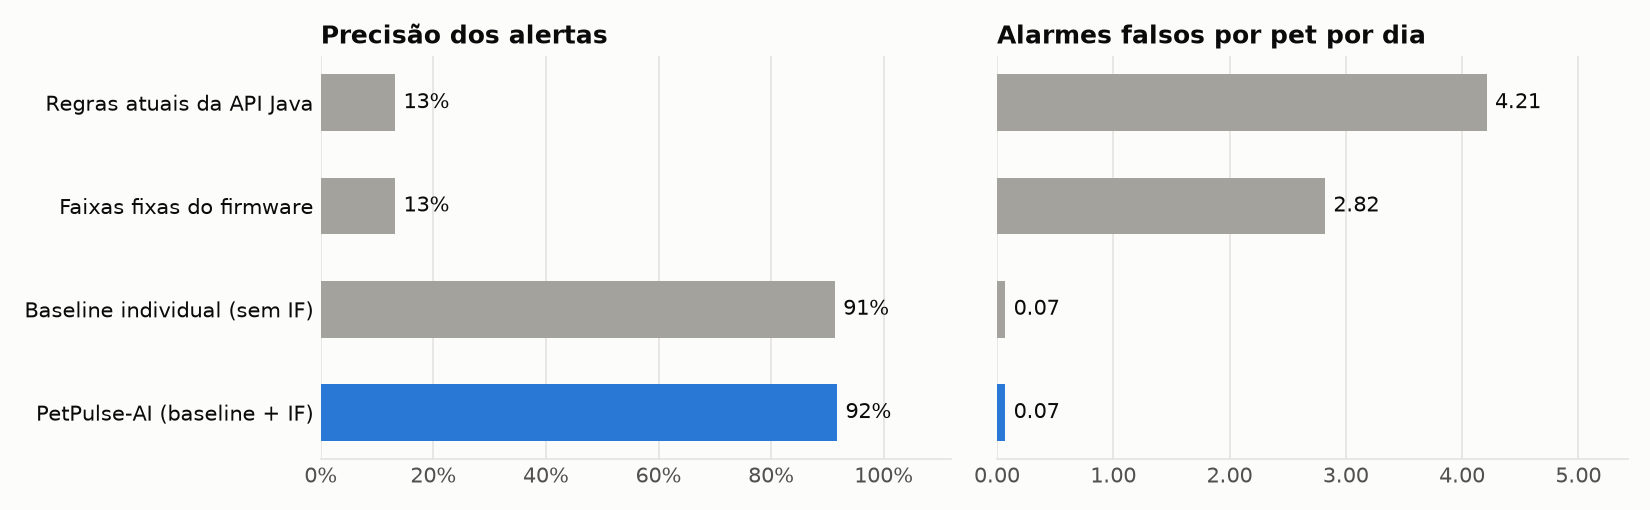

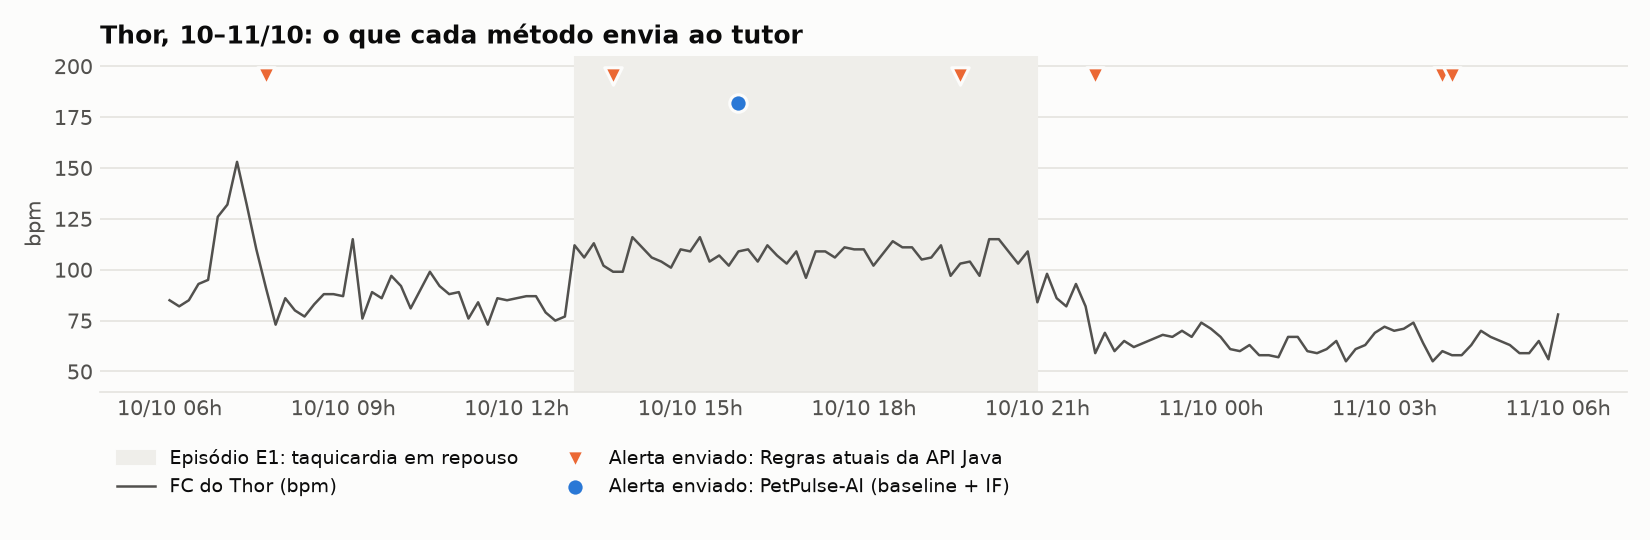

In [18]:
RODAR_AVALIACAO_COMPLETA = False

from pathlib import Path

if RODAR_AVALIACAO_COMPLETA:
    from avaliacao.avaliar import executar
    from avaliacao.graficos import main as gerar_graficos
    gerar_dataset(semente=2026, pasta=Path("dados/teste"))
    executar()
    executar(Path("dados/teste"), Path("avaliacao/teste"), "Resultados no dataset de teste (semente 2026)")
    gerar_graficos()

from IPython.display import Image

def carregar_resultados(pasta):
    return json.load(open(f"{pasta}/resultados.json", encoding="utf-8"))["resultados"]

colunas = ["metodo", "alertasEmitidos", "precisao", "recall", "f1", "falsosAlarmesPorPetDia", "latenciaMedianaH"]
print("Por episódio, dataset de desenvolvimento:")
display(pd.DataFrame(carregar_resultados("avaliacao"))[colunas])
print("Por episódio, dataset de teste (nunca visto):")
display(pd.DataFrame(carregar_resultados("avaliacao/teste"))[colunas])
display(Image("avaliacao/comparativo.png"))
display(Image("avaliacao/linha_do_tempo_thor.png"))

In [19]:
# Métricas por leitura (scikit-learn), dataset de teste
por_leitura = pd.DataFrame([
    {"metodo": r["metodo"], **{k: r["porLeitura"][k] for k in ("acuracia", "precisao", "recall", "f1")},
     "matriz de confusão [[VN, FP], [FN, VP]]": r["porLeitura"]["matrizConfusao"]}
    for r in carregar_resultados("avaliacao/teste")
])
display(por_leitura)
print("classification_report do motor PetPulse-AI (teste):")
print(carregar_resultados("avaliacao/teste")[-1]["porLeitura"]["relatorio"])

,metodo,acuracia,precisao,recall,f1,"matriz de confusão [[VN, FP], [FN, VP]]"
0,Regras atuais da API Java,0.342,0.243,1.000,0.391,"[[529, 2652], [0, 851]]"
1,Faixas fixas do firmware,0.730,0.430,0.865,0.575,"[[2206, 975], [115, 736]]"
2,Baseline individual (sem Isolation Forest),0.908,0.825,0.719,0.768,"[[3051, 130], [239, 612]]"
3,Motor PetPulse-AI (baseline + Isolation Forest),0.909,0.826,0.724,0.771,"[[3051, 130], [235, 616]]"


classification_report do motor PetPulse-AI (teste):
              precision    recall  f1-score   support

      normal       0.93      0.96      0.94      3181
    anomalia       0.83      0.72      0.77       851

    accuracy                           0.91      4032
   macro avg       0.88      0.84      0.86      4032
weighted avg       0.91      0.91      0.91      4032



Por leitura, o recall do motor é menor do que por episódio porque ele espera algumas horas de persistência antes de alertar: as primeiras leituras de cada episódio contam como "não detectadas". Foi uma escolha consciente para reduzir alarmes falsos. Para o tutor, o que importa é o episódio ser detectado.

## 12. Conclusão

- **Comparar o pet com ele mesmo foi o que fez diferença.** As regras fixas teriam mandado cerca de 4 alarmes falsos por pet por dia e não viram as taquicardias do Thor e do Bob. A nossa IA detectou os 5 episódios reais com 92% de precisão no dataset de desenvolvimento e **85% no dataset de teste**, que não foi usado no desenvolvimento. A queda é pequena, então o motor não ficou "decorado".
- **Por leitura (scikit-learn)**, o F1 do motor no teste foi 0,77, contra 0,39 das regras da API e 0,57 das faixas do firmware.
- **O contexto clínico evitou alertas injustos**, como a reação à vacina da Mel e o erro do sensor.
- **O Isolation Forest ajudou pouco nestes cenários** (92% contra 91% sem ele). O ganho principal veio da baseline individual. Mantivemos o IF porque ele confirma desvios menores e dá um score para o veterinário.
- **O Gemini deixa o alerta compreensível para o tutor**, mas sempre com os fatos calculados pelo motor e passando pelos guardrails.
- **Limitações:** os dados são sintéticos, e a IA espera algumas horas de alteração antes do alerta MÉDIO (casos graves alertam na hora). O próximo passo seria validar com dados reais de coleiras e com veterinários.

A integração com a API Java, o banco Oracle e o app está descrita no README do repositório.